In [1]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import hmp
import hmp.io
import hmp.utils
from helper_functions import *
from Least_square import run_least_squares, only, UV
from Scoring import *
from cross_validation import *
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import seaborn as sns
import mne

# Load Data from participants

In [3]:
# We need HMP predictions and real EEG data to compare.
# Workflow: HMP predictions -> predict EEG -> compare with real EEG

# ----------------------------------------------------------------------
# 0. Choose which participant to load / predict
# ----------------------------------------------------------------------
EEG_DATA_PATH = os.path.join('data')
ESTIMATION_PATH = os.path.join(EEG_DATA_PATH, 'estimation_files')

SFREQ = 250                          # use 100 for speed/RAM
TSTEP = 1000 / SFREQ                 # ms per sample, for plotting
#N_PARTICIPANTS = 2                   # how many participants to use
PARTICIPANTS = ['0', '1']


# ----------------------------------------------------------------------
# 1. Load real EEG (all participants, then keep the first 5)
# ----------------------------------------------------------------------
#subj_names = sorted([x.split('.')[0] for x in os.listdir(EEG_DATA_PATH) if x.endswith('.fif')])
#subj_files = [os.path.join(EEG_DATA_PATH, x + '.fif') for x in subj_names]

subj_files = [os.path.join(EEG_DATA_PATH, f'{p}_epo.fif') for p in PARTICIPANTS]

preprocessing = dict(sfreq=SFREQ, pick_channels='eeg')
epoch_data, info = hmp.io.read_mne_epochs(subj_files,
                                          montage='biosemi64',
                                          preprocessing_kwargs=preprocessing)

# Remove baseline that is not modelled by HMP
epoch_data = epoch_data.sel(sample=range(epoch_data.sample.max().values))

# Select only the first 2 participants
#epoch_data = epoch_data.isel(recording=range(N_PARTICIPANTS))


# ----------------------------------------------------------------------
# 2. Load HMP predictions
# ----------------------------------------------------------------------
# estimates = model outputs (event probabilities); model = the fitted model object
with open(os.path.join(ESTIMATION_PATH, 'estimates.pkl'), 'rb') as f:
    estimates = pickle.load(f)
with open(os.path.join(ESTIMATION_PATH, 'model.pkl'), 'rb') as f:
    model = pickle.load(f)

# Event topographies per trial and event (one scalp map per trial; mean=False)
weights = hmp.utils.event_channels(epoch_data, estimates, mean=False).squeeze()


# ----------------------------------------------------------------------
# Average map per participant and event: every trial of a participant gets
# the SAME map (HMP's assumption: one topography per event), so no trial
# copies its own EEG
# ----------------------------------------------------------------------
recs = weights.recording.values.astype(str)          # participant of each trial
w = weights.transpose("channel", "trial", "event").values
w_avg = w.copy()
for r in np.unique(recs):
    m = recs == r                                     # trials of participant r
    w_avg[:, m, :] = w[:, m, :].mean(axis=1, keepdims=True)
weights_avg = weights.transpose("channel", "trial", "event").copy(data=w_avg)

weights = weights_avg
# Most likely time of each event, with the RT as the last column
times = hmp.utils.event_times(estimates, add_rt=True)


Processing dataset 0
Reading /Users/ella/Desktop/NeuroX/EEG_prediction/data/0_epo.fif ...
    Found the data of interest:
        t =    -199.22 ...    3000.00 ms
        0 CTF compensation matrices available
Adding metadata with 6 columns
1116 matching events found
No baseline correction applied
0 projection items activated
Epoch data will be decimated by 2 to achieve a sampling frequency of 256.0Hz
Processing dataset 1
Reading /Users/ella/Desktop/NeuroX/EEG_prediction/data/1_epo.fif ...
    Found the data of interest:
        t =    -199.22 ...    3000.00 ms
        0 CTF compensation matrices available
Adding metadata with 6 columns
1116 matching events found
No baseline correction applied
0 projection items activated
Epoch data will be decimated by 2 to achieve a sampling frequency of 256.0Hz


In [4]:
print(weights)

<xarray.DataArray (channel: 32, trial: 2187, event: 4)> Size: 2MB
array([[[ 2.12597211e-06, -1.50990255e-06,  3.00772480e-06,
         -1.42524161e-06],
        [ 2.12597211e-06, -1.50990255e-06,  3.00772480e-06,
         -1.42524161e-06],
        [ 2.12597211e-06, -1.50990255e-06,  3.00772480e-06,
         -1.42524161e-06],
        ...,
        [ 4.04277085e-08, -1.33445665e-06,  1.92917745e-06,
         -3.03158596e-06],
        [ 4.04277085e-08, -1.33445665e-06,  1.92917745e-06,
         -3.03158596e-06],
        [ 4.04277085e-08, -1.33445665e-06,  1.92917745e-06,
         -3.03158596e-06]],

       [[ 2.30788096e-06, -1.67028177e-06,  5.27827830e-06,
         -1.53537331e-06],
        [ 2.30788096e-06, -1.67028177e-06,  5.27827830e-06,
         -1.53537331e-06],
        [ 2.30788096e-06, -1.67028177e-06,  5.27827830e-06,
         -1.53537331e-06],
...
        [ 4.76153857e-07, -2.28558383e-06,  4.16643100e-06,
         -2.28755987e-06],
        [ 4.76153857e-07, -2.28558383e-06,  4

In [5]:
# ----------------------------------------------------------------------
# 3. Keep only the trials of the participants we selected
# ----------------------------------------------------------------------
recs = [str(r) for r in epoch_data.recording.values]
keep = np.where(np.isin(times.recording.values.astype(str), recs))[0]
# times: covers the whole model -> subset to the selected participants
keep_t = np.where(np.isin(times.recording.values.astype(str), recs))[0]
times = times.isel(trial=keep_t)


# Check that both refer to the same (recording, epoch) trials in the same order
t_ids = list(zip(times.recording.values.astype(str), times.epoch.values))
w_ids = list(zip(weights.recording.values.astype(str), weights.epoch.values))

# weights: already built from epoch_data, to have same order
weights = weights.isel(trial=[w_ids.index(t) for t in t_ids])

print("trials in times:", len(t_ids), "| trials in weights:", len(w_ids))
print("Same trials, same order:", t_ids == w_ids)

print("Participants:", recs, "| trials in model:", len(keep),
      "| epochs in data:", epoch_data.epoch.size * len(recs))
print("Channels in data:", epoch_data.channel.size, "| weights shape:", weights.shape)
print("NaNs in weights:", int(np.isnan(weights).sum()))


trials in times: 2187 | trials in weights: 2187
Same trials, same order: True
Participants: ['0', '1'] | trials in model: 2187 | epochs in data: 2232
Channels in data: 32 | weights shape: (32, 2187, 4)
NaNs in weights: 0


In [9]:
# ----------------------------------------------------------------------
# 4. Keep in epoch_data only the trials used by HMP (rejected trials -> NaN)
# ----------------------------------------------------------------------
# (recording, epoch) pairs kept by HMP
kept = set(zip(times.recording.values.astype(str), times.epoch.values.astype(int)))

# True where the (recording, epoch) pair was kept by HMP
mask = xr.DataArray(
    np.array([[(str(r), int(e)) in kept for e in epoch_data.epoch.values]
              for r in epoch_data.recording.values]),
    dims=("recording", "epoch"),
    coords={"recording": epoch_data.recording, "epoch": epoch_data.epoch},
)

# Rejected trials (and empty grid cells) become NaN
epoch_data = epoch_data.where(mask)

# Check: number of non-empty trials should equal the number of trials in times
n_real = int(epoch_data["data"].notnull().any(["channel", "sample"]).sum())
print("trials in epoch_data:", n_real, "| trials in times:", times.trial.size)

trials in epoch_data: 2187 | trials in times: 2187


In [7]:
# ----------------------------------------------------------------------
# 5. Cut every trial at its RT: HMP only models stimulus -> response
# ----------------------------------------------------------------------
last_dim = [d for d in times.dims if d != "trial"][0]
rt_vals = times.isel({last_dim: -1}).values                  # RT in samples
lookup = {(str(r), int(e)): v for r, e, v in
          zip(times.recording.values, times.epoch.values, rt_vals)}

rt_grid = xr.DataArray(
    [[lookup.get((str(r), int(e)), -1) for e in epoch_data.epoch.values]
     for r in epoch_data.recording.values],
    dims=("recording", "epoch"),
    coords={"recording": epoch_data.recording, "epoch": epoch_data.epoch},
)

epoch_data = epoch_data.where(epoch_data.sample < rt_grid)    # NaN from RT onwards

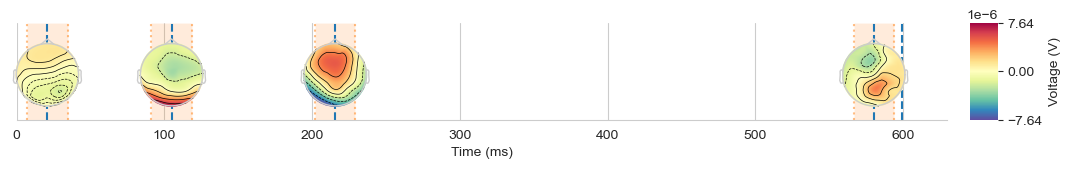

In [8]:
hmp.visu.plot_topo_timecourse(epoch_data, estimates, info, as_time=True, colorbar=True,)

# 1.1 Basic EEG Simulation 

In [10]:
# An example using the default assumption of HMP regarding the pattern in the data
pattern_assumption = {0:HalfSine(SFREQ, width=50), 1:HalfSine(SFREQ, width=50), 
                      2:HalfSine(SFREQ, width=50), 3:HalfSine(SFREQ, width=50)}
# one pattern by event (here 4 events)
default_sim = simulate_from_hmpfit(epoch_data, weights, times, pattern_assumption)
print(default_sim)

<xarray.Dataset> Size: 220MB
Dimensions:     (recording: 2, epoch: 1116, channel: 32, sample: 768)
Coordinates:
  * recording   (recording) <U1 8B '0' '1'
  * epoch       (epoch) int64 9kB 0 1 2 3 4 5 ... 1110 1111 1112 1113 1114 1115
    event_name  (recording, epoch) object 18kB 'stimulus/95' ... 'stimulus/25'
    rt          (recording, epoch) float64 18kB 0.7197 0.4502 ... 0.4609 0.4082
    condition   (recording, epoch) object 18kB 'accuracy' 'accuracy' ... 'speed'
    side        (recording, epoch) object 18kB 'right' 'right' ... 'right'
    stimulus    (recording, epoch) object 18kB '95' '29' '42' ... '71' '42' '25'
    response    (recording, epoch) object 18kB 'left' 'right' ... 'left' 'right'
    subject     (recording, epoch) <U1 9kB '0' '0' '0' '0' ... '1' '1' '1' '1'
  * channel     (channel) <U3 384B 'Fp1' 'AF3' 'F7' 'F3' ... 'Fp2' 'Fz' 'Cz'
  * sample      (sample) int64 6kB 0 1 2 3 4 5 6 ... 761 762 763 764 765 766 767
Data variables:
    data        (recording, epoch, 

Text(0.5, 1.0, 'Default Half-Sine')

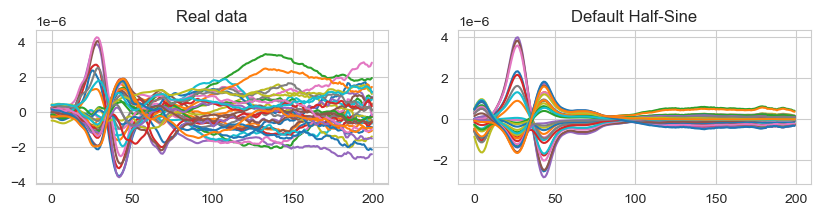

In [11]:
# Plotting the simulation
fig, ax = plt.subplots(1,2, figsize=(10, 2), sharey=False)
ax[0].plot(epoch_data.sel(sample=range(200)).stack({'trial':['epoch','recording']}).mean('trial').data.T);
ax[0].set_title('Real data')
ax[1].plot(default_sim.sel(sample=range(200)).stack({'trial':['epoch','recording']}).mean('trial').data.T);
ax[1].set_title('Default Half-Sine')

In [24]:
# Grand average: level or amplitude? On the window where >= 50 % of trials remain
n_trials = epoch_data["data"].isel(channel=0).notnull().sum(["recording", "epoch"])
frac = n_trials / n_trials.sel(sample=0)
cut = int(frac.sample[frac >= 0.5].max())

kw = dict(average_trial=True, average_participant=True, average_channel=True)
r, p = epoch_data.sel(sample=range(cut)), default_sim.sel(sample=range(cut))
r2 = float(score(r, p, "r2", **kw))
ev = float(score(r, p, "explained_variance", **kw))
c  = float(score(r, p, "corr", **kw))
print(f"window 0-{cut} samples | R2 = {r2:.3f} | EV (no level) = {ev:.3f} | corr^2 = {c**2:.3f}")

window 0-138 samples | R2 = 0.243 | EV (no level) = 0.586 | corr^2 = 0.599


Interpretation (window 0–138 samples ≈ 540 ms, ≥ 50 % of trials)
Step	Score	What it shows
R²	0.243	positive on the clean window
EV (level removed)	0.586	+0.34 just by removing the level, so the offset costs a lot
corr² (amplitude removed too)	0.599	≈ EV, so amplitude is not a problemInterpretation (window 0–138 samples ≈ 540 ms, ≥ 50 % of trials)
Step	Score	What it shows
R²	0.243	positive on the clean window
EV (level removed)	0.586	+0.34 just by removing the level, so the offset costs a lot
corr² (amplitude removed too)	0.599	≈ EV, so amplitude is not a problem

# 1.2 Score Prediction

### R2 score: 

In [13]:
# ----------------------------------------------------------------------
# Case 1: nothing averaged -> one score per trial and per electrode
# "How well does HMP predict each single trial?"
# dims: (recording, epoch, channel)
# ----------------------------------------------------------------------
r2_trials = score(epoch_data, default_sim, "r2")

# ----------------------------------------------------------------------
# Case 2: trials averaged -> one score per participant and per electrode
# "How well does HMP predict each participant's average signal (ERP)?"
# dims: (recording, channel)
# ----------------------------------------------------------------------
r2_erp = score(epoch_data, default_sim, "r2", average_trial=True)

# ----------------------------------------------------------------------
# Case 2b: trials and participants averaged -> one score per electrode
# "How well does HMP predict the grand-average signal, on each electrode?"
# dims: (channel,)
# ----------------------------------------------------------------------
r2_grand = score(epoch_data, default_sim, "r2",
                 average_trial=True, average_participant=True)

# ----------------------------------------------------------------------
# Case 3: everything averaged -> one single number
# dims: none (a scalar)
# ----------------------------------------------------------------------
r2_global = score(epoch_data, default_sim, "r2",
                  average_trial=True, average_participant=True, average_channel=True)

print("Case 1  :", r2_trials.shape)
print("Case 2  :", r2_erp.shape)
print("Case 2b :", r2_grand.shape)
print("Case 3  :", float(r2_global))

Case 1  : (2, 1116, 32)
Case 2  : (2, 32)
Case 2b : (32,)
Case 3  : -0.3565106303188137


In [14]:
print(r2_grand)

<xarray.DataArray (channel: 32)> Size: 256B
array([-0.47837025, -0.63874418, -0.91602989, -0.33069645, -0.43647108,
       -0.24244801, -0.01538347, -0.09396812, -0.80453343, -0.18281581,
       -0.13130632, -0.52349751,  0.07952921, -0.28656194, -0.23157793,
       -0.65025696, -0.05431485, -0.54907248, -0.68350321, -0.00532673,
       -0.08835183, -0.00382158, -0.29678504, -0.38340925, -0.14099789,
       -0.67467855,  0.00170996, -0.02972301, -0.70149249, -0.79875742,
       -0.15911067, -0.95757301])
Coordinates:
  * channel  (channel) <U3 384B 'Fp1' 'AF3' 'F7' 'F3' ... 'AF4' 'Fp2' 'Fz' 'Cz'


## R2 score per event:

In [15]:
window_ms = 50                                   # total window width in ms
half_width = round(window_ms / 1000 * SFREQ / 2) # = 6 at 250 Hz. The window is [event_time - half_width, event_time + half_width]
r2_window = score_event_windows(epoch_data, default_sim, times, half_width)
print(r2_window.mean("channel"))      # one value per event

<xarray.DataArray (event: 4)> Size: 16B
array([0.00922002, 0.02078741, 0.01859935, 0.00815325], dtype=float32)
Coordinates:
  * event    (event) int64 32B 0 1 2 3


### Correlation

In [16]:
# one trial: (samples, channels)
real = epoch_data.sel(sample=range(200)).stack(trial=['epoch', 'recording']).mean('trial')['data'].transpose('sample', 'channel').values
sim  = default_sim.sel(sample=range(200)).stack({'trial':['epoch','recording']}).mean('trial')['data'].transpose('sample', 'channel').values

print(pearson(real, sim))   # array of shape (n_channels,)

[0.8149723  0.8120742  0.51385146 0.9326708  0.8347874  0.744012
 0.32736158 0.8232885  0.5246376  0.23523805 0.7669454  0.58293813
 0.78656065 0.88951224 0.9023252  0.9225635  0.8078587  0.6808608
 0.07875863 0.72553027 0.09083352 0.77141976 0.7642109  0.7231185
 0.35424367 0.9089073  0.6862498  0.6225251  0.48787242 0.33538213
 0.9011738  0.7504347 ]


# 2. Cross-validation: Model tuning, how should we build prediction
The procedure:
1. Split into test and train set.
2. On training data, run K-fold cross-validation. For each candidate value (for example widths of 30, 50, 80 and 120 ms), fit the weights on the training folds, predict the held-out fold, and score it against the real EEG, with pooled R² as the main number.
3. Average the held-out scores across folds and take the best candidate.
4. Report the chosen recipe once, on the final test set, so the result isn't optimistic from the selection.

5 folds, window = +-all samples, 24 widths, 4 events
pass 1, event 0: best width 40 ms (mean R2 = 0.0119)
pass 1, event 1: best width 50 ms (mean R2 = 0.0119)
pass 1, event 2: best width 60 ms (mean R2 = 0.0123)
pass 1, event 3: best width 380 ms (mean R2 = 0.0140)
pass 2, event 0: best width 40 ms (mean R2 = 0.0140)
pass 2, event 1: best width 50 ms (mean R2 = 0.0140)
pass 2, event 2: best width 60 ms (mean R2 = 0.0140)
pass 2, event 3: best width 380 ms (mean R2 = 0.0140)
tuned {0: np.int64(40), 1: np.int64(50), 2: np.int64(60), 3: np.int64(380)} overall R2 = 0.0157 event windows: [0.014 0.039 0.027 0.001]
baseline {0: 50, 1: 50, 2: 50, 3: 50} overall R2 = 0.0128 event windows: [ 0.012  0.04   0.025 -0.001]


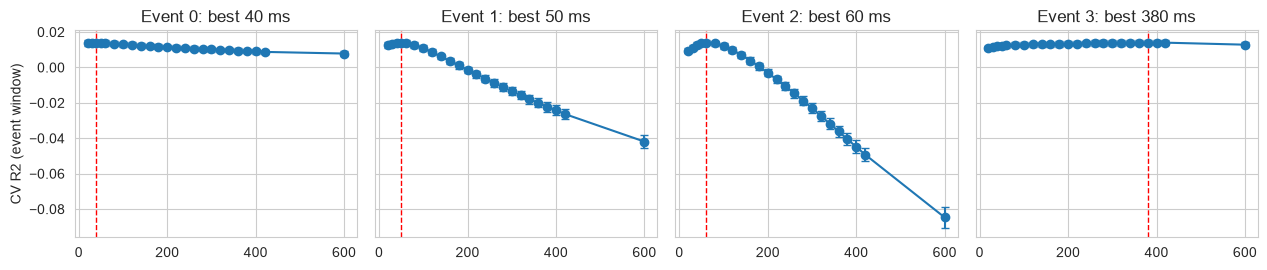

In [15]:
HW = 12   # same window for CV and evaluation

tuner = EventWidthCV(epoch_data, times, weights, SFREQ)
# builds the object that holds everything. 1. Converts the real EEG to microvolts and flattens it into a list of "points". A point is one sample, from one trial, on all 32 electrodes. Only samples between stimulus onset (0) and the RT with no NaN are kept. 2. Stores, for each trial, the HMP event times and the RT. 3.Puts HMP weights (channel, trial, event) onto the same (recording, epoch) grid, in the electrode order of epoch_data.
test_mask = split_trials(epoch_data, test_frac=0.2, seed=0) # split into test train set
folds = kfold_masks(epoch_data, k=5, seed=0, exclude=test_mask) # splits training data into 5 folds and returns 5 pairs
grid =[20, 30, 40, 50, 60, 80, 100, 120, 140, 160, 180, 200, 220, 240, 260, 280, 300, 320, 340, 360, 380, 400, 420, 600]
cv, best = tuner.cross_validate(grid, folds,half_width="all", n_passes=5) 
plot_cv(cv)
# For each event e (0 to 3) and each candidate width w in ms:
# 1. Build the half-sine bump of event e with width w. The other events keep their latest width (start: 50 ms). Events are updated one after the other, so event 1 already sees the new width of event 0. 
# 2. Reconstruct the EEG as pred[c,t] = sum_e W[trial,e,c] * T_e(t) with the fixed HMP weights.
# 3. Compute R2 on ALL samples before the RT of the validation trials (same score for every event, so the search converges), per electrode, averaged over electrodes, separately for each of the 5 folds. The width with the highest mean R2 over the folds becomes the new width of event e. Passes repeat until no width changes (max n_passes). cv has one row per (pass, event, width, fold). best is the dict of final widths, e.g. {0: 60, 1: 60, ...}.

res_tuned = tuner.evaluate(best, test_mask, half_width=HW)
# This reconstructs the test trials with the tuned widths and the HMP weights, and returns: r2_overall: R² over all test samples, averaged over electrodes. r2_event_windows: R² inside each event's window (±6 samples). r2_overall_per_channel: the same overall R², per electrode.
res_base  = tuner.evaluate({e: 50 for e in range(4)}, test_mask, half_width=HW) # baseline
for name, r in [("tuned", res_tuned), ("baseline", res_base)]:
    print(name, r["widths"], f"overall R2 = {r['r2_overall']:.4f}",
          "event windows:", np.round(r["r2_event_windows"], 3))


Text(0.5, 1.0, 'Tuned Half-Sine')

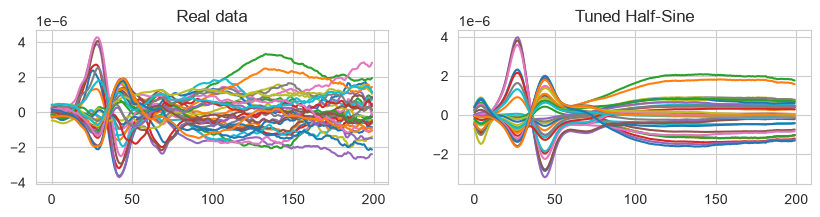

In [16]:
# Simulate with the tuned widths (and the 50 ms baseline for comparison)
templates = make_templates(best, SFREQ)
tuned_sim = simulate_from_hmpfit(epoch_data, weights, times, templates)

# Plotting the simulation
fig, ax = plt.subplots(1,2, figsize=(10, 2), sharey=False)
ax[0].plot(epoch_data.sel(sample=range(200)).stack({'trial':['epoch','recording']}).mean('trial').data.T);
ax[0].set_title('Real data')
ax[1].plot(tuned_sim.sel(sample=range(200)).stack({'trial':['epoch','recording']}).mean('trial').data.T);
ax[1].set_title('Tuned Half-Sine')


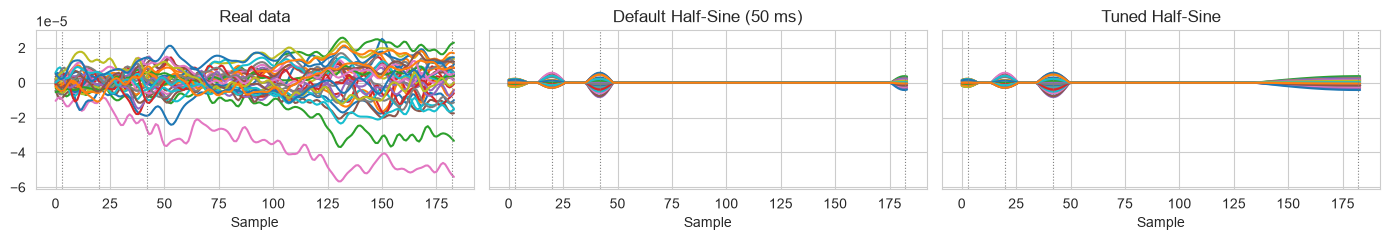

In [17]:
k = 0                                    # k-th usable trial; change to look at others
ri, ei = tuner._trials[k]                # position in (recording, epoch)
rt = int(tuner.rt[ri, ei])               # response time in samples

def one_trial(ds):
    return ds.isel(recording=ri, epoch=ei).isel(sample=slice(0, rt))["data"]

fig, ax = plt.subplots(1, 3, figsize=(14, 2.5), sharey=True)   # sharey so amplitudes are comparable
for a, ds, title in zip(ax, [epoch_data, default_sim, tuned_sim],
                        ["Real data", "Default Half-Sine (50 ms)", "Tuned Half-Sine"]):
    a.plot(one_trial(ds).values.T)       # (channel, sample).T -> one line per electrode
    a.set_title(title)
    for e in range(tuner.n_events):      # HMP event times of this trial
        a.axvline(tuner.ev_time[ri, ei, e], color="grey", ls=":", lw=0.8)
    a.set_xlabel("Sample")
plt.tight_layout()

# 3. Model implementations
## 3.1 Least square implementation
The idea is to see whether we can find some weights shared across trials that output a better approximation of the initial EEG and that we can also use across a test data set for which the weights were not trained on.

In [12]:
from Least_square import run_least_squares_participants, only

out = run_least_squares_participants(epoch_data, weights, times, pattern_assumption,
                        test_frac=0.2, seed=0, by="trial")
test = out["test_mask"]

# one score per electrode 
r2_test_per_electrode  = score(only(out["real_uv"], test),  only(out["pred_uv"], test),  "r2",average_trial=True, average_participant=True) 
r2_train_per_electrode = score(only(out["real_uv"], ~test), only(out["pred_uv"], ~test), "r2", average_trial=True, average_participant=True)

In [13]:
#one overall score: 
r2_test_overall  = score(only(out["real_uv"], test),  only(out["pred_uv"], test),  "r2",average_trial=True, average_participant=True,average_channel=True) 
r2_train_overall = score(only(out["real_uv"], ~test), only(out["pred_uv"], ~test), "r2", average_trial=True, average_participant=True,average_channel=True)
print(r2_train_overall)
print(r2_test_overall)

<xarray.DataArray ()> Size: 8B
array(-0.28955048)
<xarray.DataArray ()> Size: 8B
array(-0.24085846)


## R2 score per event

In [16]:
window_ms = 50                                   # total window width in ms
half_width = round(window_ms / 1000 * SFREQ / 2) # = 6 at 250 Hz. The window is [event_time - half_width, event_time + half_width]

r2_win_train = score_event_windows(out["real_uv"], out["pred_uv"], times, half_width,
                                   trial_mask=~test)
r2_win_test = score_event_windows(out["real_uv"], out["pred_uv"], times, half_width,
                                   trial_mask=out["test_mask"])
print(r2_win_train.mean("channel"))
print(r2_win_test.mean("channel"))

<xarray.DataArray (event: 4)> Size: 32B
array([0.00493004, 0.02220397, 0.02291935, 0.01675585])
Coordinates:
  * event    (event) int64 32B 0 1 2 3
<xarray.DataArray (event: 4)> Size: 32B
array([6.22788865e-05, 2.40115429e-02, 2.05829332e-02, 7.60861624e-03])
Coordinates:
  * event    (event) int64 32B 0 1 2 3


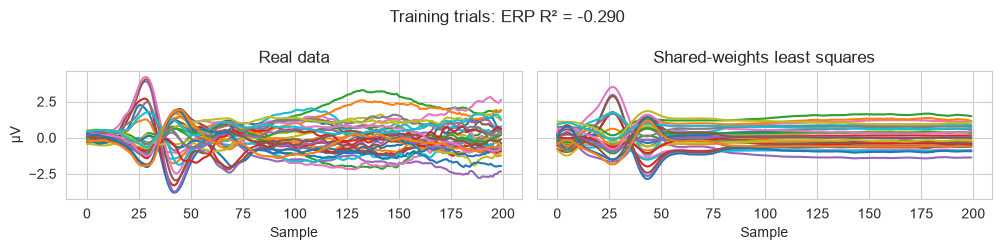

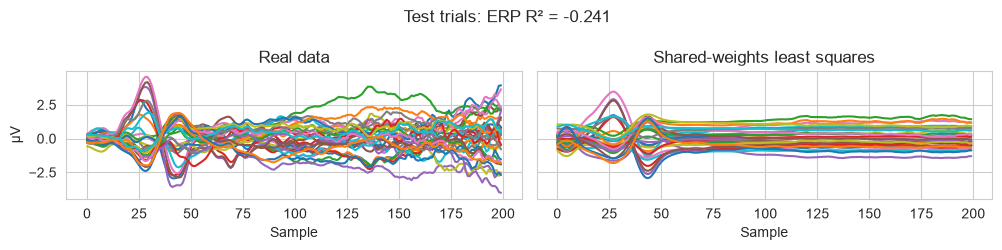

In [17]:
def plot_erp(real_ds, pred_ds, mask, r2, title_prefix, n=200):
    fig, ax = plt.subplots(1, 2, figsize=(10, 2.5), sharey=True)
    for a, ds, name in zip(ax, [only(real_ds, mask), only(pred_ds, mask)],
                           ['Real data', 'Shared-weights least squares']):
        d = ds['data'] if n is None else ds['data'].sel(sample=range(n))
        erp = d.stack(trial=['epoch', 'recording']).mean('trial', skipna=True)
        a.plot(erp.transpose('sample', 'channel').values)
        a.set_title(name)
        a.set_xlabel('Sample')
    ax[0].set_ylabel('µV')
    fig.suptitle(f"{title_prefix}: ERP R² = {float(r2):.3f}")
    plt.tight_layout()

args = dict(real_ds=out["real_uv"], pred_ds=out["pred_uv"])
plot_erp(**args, mask=~test, r2=r2_train_overall, title_prefix="Training trials")
plot_erp(**args, mask=test,  r2=r2_test_overall,  title_prefix="Test trials")


Learning the weights with Least square on a training data set and testing them on a test data set results in a very low R2 score. To see what R2 score is even possible to achieve, we tried to compute the best possible weights for each trial, each participant individually. 

### Best possible output with Least squares (don't combine weights but fit least square for each individual trial and person) + add an intercept so that R2 is not negative

In [19]:
from Least_square import event_traces, fit_per_trial, noise_floor

traces = event_traces(epoch_data, weights, times, pattern_assumption)
real_uv = epoch_data.copy()
real_uv["data"] = epoch_data["data"] * 1e6

W_trial, ub_ds = fit_per_trial(real_uv, traces)

# score
r2_ub_trials = score(real_uv, ub_ds, "r2")                     # per trial and electrode
r2_ub_erp    = score(real_uv, ub_ds, "r2", average_trial=True,
                     average_participant=True, average_channel=True)

In [20]:
print("Median of R2 score per trial and electrode:",float(r2_ub_trials.median(skipna=True)))
print("Overall R2 score:", float(r2_ub_erp))

Median of R2 score per trial and electrode: 0.2507052762608436
Overall R2 score: 0.5858388553218634


Voltage at each electrode, averaged over all trials and participants:


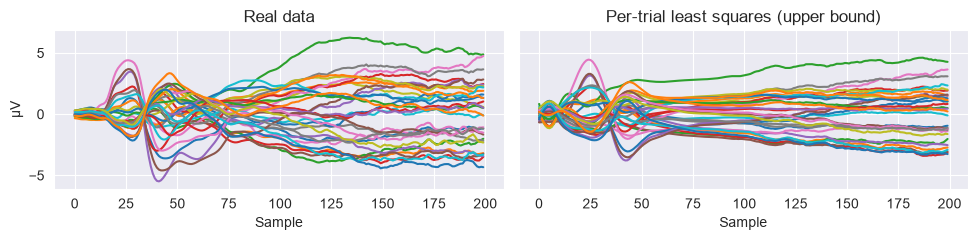

In [21]:
#each line is one electrode, averaged over all trials and participants
n = 200
fig, ax = plt.subplots(1, 2, figsize=(10, 2.5), sharey=True)
print("Voltage at each electrode, averaged over all trials and participants:")
for a, ds, title in zip(ax,[real_uv, ub_ds],['Real data', 'Per-trial least squares (upper bound)']):
    erp = (ds['data'].sel(sample=range(n)).stack(trial=['epoch', 'recording']).mean('trial', skipna=True))# grand-average ERP: channel x sample
    a.plot(erp.transpose('sample', 'channel').values)
    a.set_title(title)
    a.set_xlabel('Sample')
ax[0].set_ylabel('µV')
plt.tight_layout()

Voltage at each electrode in one single trial:


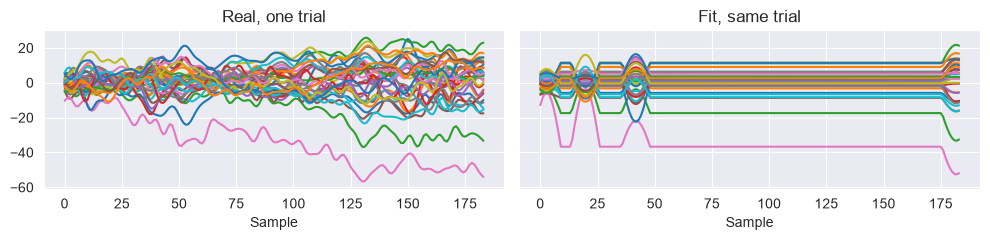

In [22]:
# each line is one electrode in a single trial, with no averaging
# first trial that has data
has_data = real_uv['data'].notnull().any(['channel', 'sample'])
rec_i, ep_i = [int(i[0]) for i in np.where(has_data.values)]
print("Voltage at each electrode in one single trial:")
fig, ax = plt.subplots(1, 2, figsize=(10, 2.5), sharey=True)
for a, ds, title in zip(ax, [real_uv, ub_ds], ['Real, one trial', 'Fit, same trial']):
    tr = ds['data'].isel(recording=rec_i, epoch=ep_i).transpose('sample', 'channel')
    a.plot(tr.values)
    a.set_title(title)
    a.set_xlabel('Sample')
plt.tight_layout()

### R2 score per event

In [54]:
r2_win_best = score_event_windows(real_uv, ub_ds, times, half_width)
print(r2_win_best.mean("channel"))

<xarray.DataArray (event: 4)> Size: 16B
array([0.5360085 , 0.6443218 , 0.7533636 , 0.86682606], dtype=float32)
Coordinates:
  * event    (event) int64 32B 0 1 2 3


## R2 if EEG is just noise

In [23]:
n_events = weights.sizes["event"]          # 4 in your case
floor = noise_floor(real_uv, n_events)     # DataArray (recording, epoch)-> for each subject, for each trial we get the noise floor

print(floor)
print("median noise floor:", float(floor.median(skipna=True)))

<xarray.DataArray 'data' (recording: 2, epoch: 1117)> Size: 18kB
array([[0.02185792, 0.03508772, 0.02409639, ..., 0.02684564, 0.02515723,
               nan],
       [0.02116402, 0.02631579, 0.03669725, ..., 0.01114206, 0.02515723,
               nan]], shape=(2, 1117))
Coordinates:
  * recording   (recording) <U2 16B '0' '10'
    subject     (recording) <U2 16B '0' '10'
  * epoch       (epoch) int64 9kB 0 1 2 3 4 5 ... 1111 1112 1113 1114 1115 1116
    event_name  (recording, epoch) object 18kB 'stimulus/95' ... nan
    rt          (recording, epoch) float64 18kB 0.7197 0.4502 ... 0.623 nan
    condition   (recording, epoch) object 18kB 'accuracy' 'accuracy' ... nan
    side        (recording, epoch) object 18kB 'right' 'right' ... 'left' nan
    stimulus    (recording, epoch) object 18kB '95' '29' '42' ... '26' '42' nan
    response    (recording, epoch) object 18kB 'left' 'right' ... 'left' nan
median noise floor: 0.028169014084507043


In [24]:
#Comparing noise floor R2 value with predictions/reconstruction:

ub_per_trial = r2_ub_trials.mean("channel", skipna=True)   # (recording, epoch) to get same dimension as noise floor, averages for all electrodes

ub_med = float(ub_per_trial.median(skipna=True))  #takes median R2
fl_med = float(floor.median(skipna=True))    #takes median noise R2
print(f"upper bound (median trial): {ub_med:.3f}")
print(f"noise floor (median trial): {fl_med:.3f}")
print(f"ratio: {ub_med / fl_med:.1f}x")

# trial by trial: is the bound above the floor?
above = (ub_per_trial > floor).where(ub_per_trial.notnull())   #computes the fraction of trials where the fitted upper bound beats the noise floor.
print("share of trials above the floor:", float(above.mean(skipna=True))) 

upper bound (median trial): 0.264
noise floor (median trial): 0.028
ratio: 9.4x
share of trials above the floor: 1.0


ratio of 1 means every scored trial had an upper-bound R² higher than its own noise floor.

median R2 fitting pure noise: 0.13527017518532564
median R2 fitting real EEG  : 0.26366089182052577


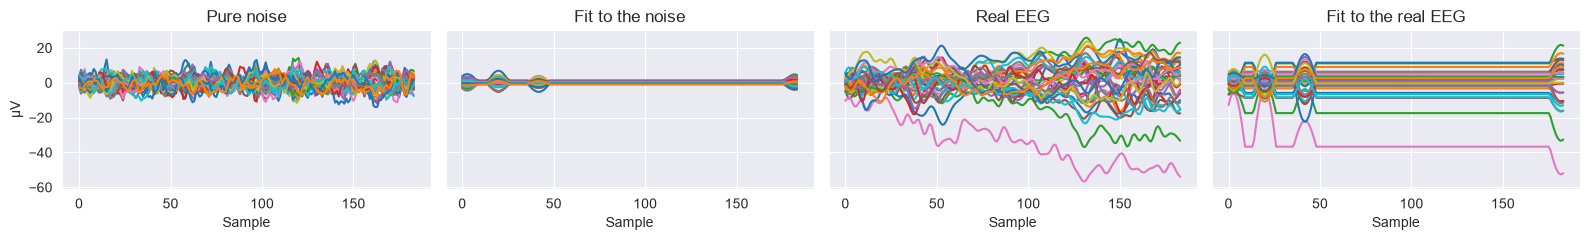

In [35]:
# pure noise, same shape as the data, in µV
noise_ds = simulate_from_hmpfit(epoch_data, weights * 0, times, pattern_assumption, add_noise=True)
noise_uv = noise_ds.copy()
noise_uv["data"] = noise_ds["data"] * UV

# fit the same per-trial model (bumps + intercept) to the noise
W_n, noise_fit = fit_per_trial(noise_uv, traces)

r2_noise = score(noise_uv, noise_fit, "r2").mean("channel", skipna=True)
print("median R2 fitting pure noise:", float(r2_noise.median(skipna=True)))
print("median R2 fitting real EEG  :", float(ub_per_trial.median(skipna=True)))

# one trial: noise vs the fit to it, next to real EEG vs its fit
has = noise_uv["data"].notnull().any(["channel", "sample"])
ri, ei = [int(i[0]) for i in np.where(has.values)]

fig, ax = plt.subplots(1, 4, figsize=(16, 2.5), sharey=True)
for a, ds, title in zip(ax, [noise_uv, noise_fit, real_uv, ub_ds],
                        ["Pure noise", "Fit to the noise", "Real EEG", "Fit to the real EEG"]):
    a.plot(ds["data"].isel(recording=ri, epoch=ei).transpose("sample", "channel").values)
    a.set_title(title)
    a.set_xlabel("Sample")
ax[0].set_ylabel("µV")
plt.tight_layout()

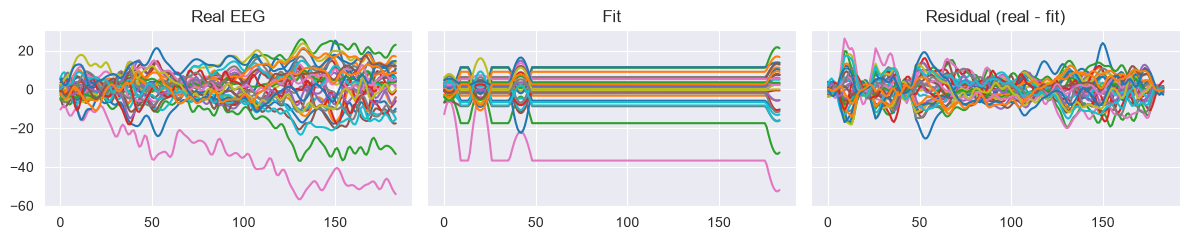

In [36]:
#plot of the residual for one trial/ the part of the real EEG data least square doesn't explain
resid = real_uv.copy()
resid["data"] = real_uv["data"] - ub_ds["data"]      # real minus fit

fig, ax = plt.subplots(1, 3, figsize=(12, 2.5), sharey=True)
for a, ds, title in zip(ax, [real_uv, ub_ds, resid], ["Real EEG", "Fit", "Residual (real - fit)"]):
    a.plot(ds["data"].isel(recording=ri, epoch=ei).transpose("sample", "channel").values)
    a.set_title(title)
plt.tight_layout()

In [38]:
rng = np.random.default_rng(0)
r = resid["data"].sel(sample=range(n)).stack(trial=["epoch", "recording"])

stds = []
for _ in range(50):
    signs = xr.DataArray(rng.choice([-1, 1], size=r.sizes["trial"]), dims="trial")
    stds.append(float((r * signs).mean("trial", skipna=True).std()))

print("noise-only ERP std:", np.mean(stds))
print("residual ERP std  :", float(resid_erp.std()))

noise-only ERP std: 0.13202150999458254
residual ERP std  : 0.714117705821991


The residual ERP is far above the noise level (0.71 vs 0.13 µV), so what's left is mostly consistent, time-locked structure that the model misses, not leftover noise. In variance terms, noise explains about (0.13/0.71)² ≈ 3% of the residual ERP's variance. So the model captures a lot of the ERP (the residual is about 13% of its variance), but the remaining 13% is systematic, not random.

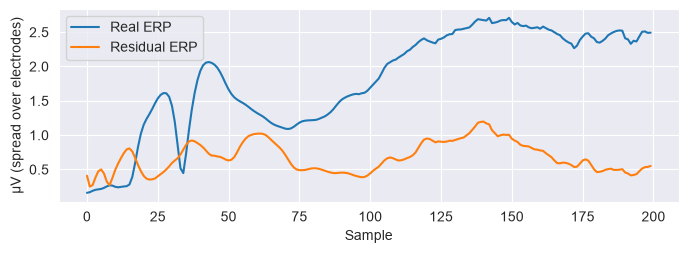

In [39]:
# See when the residual is large: Plot of the spatial spread over time for the real ERP and the residual ERP:
gfp_real  = real_erp.std("channel")      # spread across electrodes at each sample
gfp_resid = resid_erp.std("channel")

plt.figure(figsize=(8, 2.5))
plt.plot(gfp_real.values,  label="Real ERP")
plt.plot(gfp_resid.values, label="Residual ERP")
plt.xlabel("Sample"); plt.ylabel("µV (spread over electrodes)"); plt.legend()

- Samples 0 to 15: the residual is larger than the real ERP (about 0.4 to 0.8 against 0.2). The real average is nearly flat there, so the fit is adding structure that isn't in the data.
- Samples 20 to 60: the two early peaks (about 28 and 43) are fitted reasonably. The residual stays around 0.4 to 1.0. It bumps up at 37 and 60, in between and after the real peaks -> so the timing or width isn't quite right, but this part works.
- Samples 100 to 200: the largest absolute and relative misfit. The real ERP rises to a broad plateau of about 2.5 that lasts roughly 100 samples (400 ms), and the residual climbs to 1.2 at around sample 140, close to half the signal. A 50 ms half-sine can't represent a sustained, slowly rising component like this, so most of it is left in the residual.

# Visualizations

NameError: name 'participant_id' is not defined

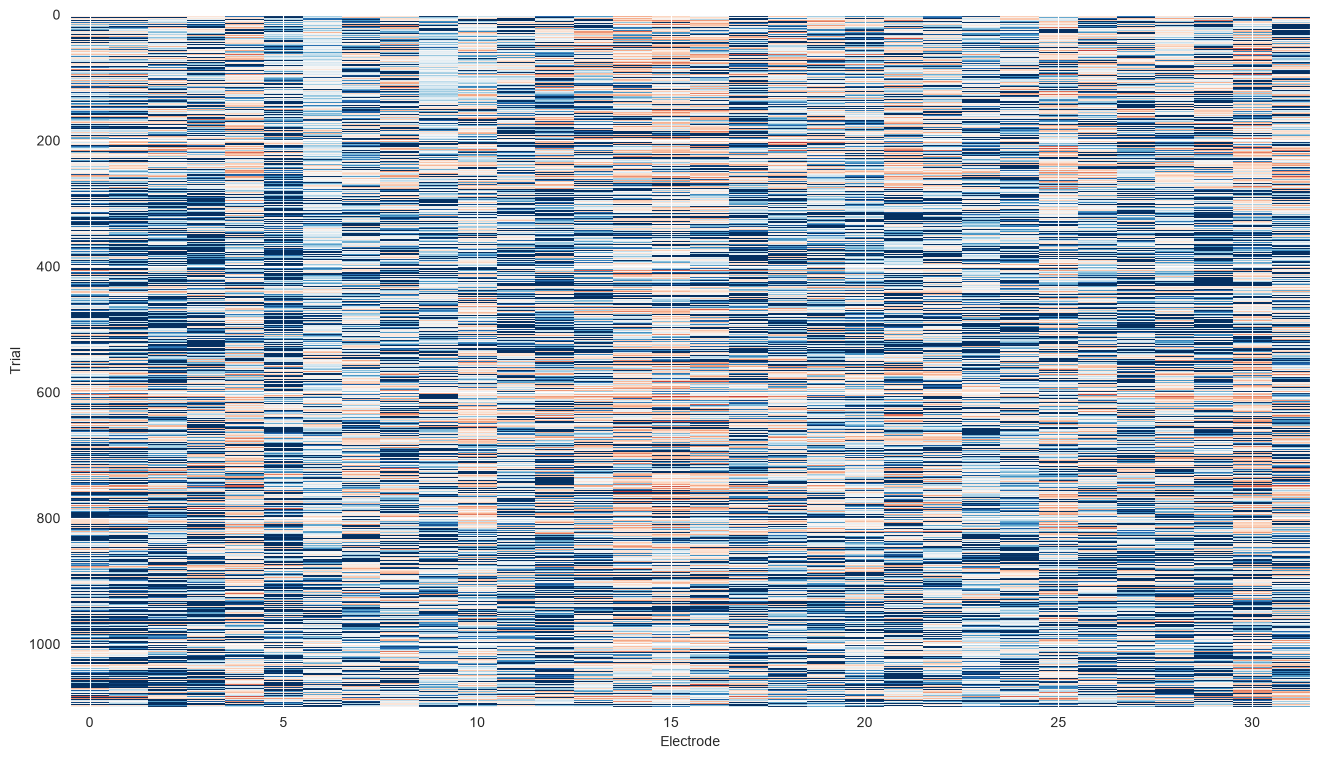

In [25]:
# Select one participant
participant = "10"

r2_heatmap = r2_trials.sel(recording=participant)

# Remove epochs with no valid scores
valid_epochs = r2_heatmap.notnull().any("channel")
r2_heatmap = r2_heatmap.sel(epoch=r2_heatmap.epoch[valid_epochs])

fig, ax = plt.subplots(figsize=(16, 9))

im = ax.imshow(
    r2_heatmap.values,
    aspect="auto",
    cmap="RdBu_r",
    interpolation="nearest",
    vmin=-1,
    vmax=1
)

ax.set_xlabel("Electrode")
ax.set_ylabel("Trial")
ax.set_title(f"R² per Trial and Electrode - Participant {participant_id}")

ax.set_xticks(range(len(r2_heatmap.channel)))
ax.set_xticklabels(r2_heatmap.channel.values, rotation=60, ha="right")

plt.colorbar(im, ax=ax, label="R²")
plt.tight_layout()
plt.show()


In [237]:
print(r2_trials.recording.values)

['0' '10']


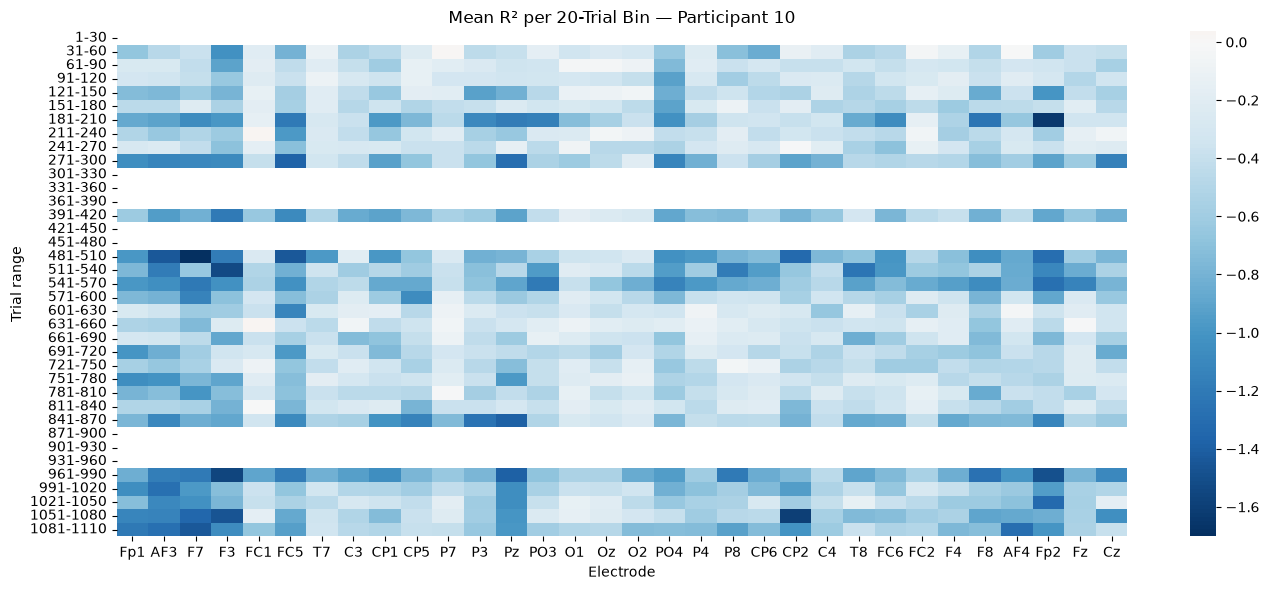

In [238]:
# Average every 30 consecutive trials
n_per_bin = 30

n_epochs = participant_data.sizes["epoch"]
n_bins = n_epochs // n_per_bin

# Keep complete bins
data = participant_data.isel(
    epoch=slice(0, n_bins * n_per_bin)
)

# Reshape into bins and average
binned_data = data.values.reshape(
    n_bins, n_per_bin, data.sizes["channel"]
).mean(axis=1)

plt.figure(figsize=(14, 6))

sns.heatmap(
    binned_data,
    cmap="RdBu_r",
    center=0,
    xticklabels=participant_data.channel.values,
    yticklabels=[f"{i*n_per_bin+1}-{(i+1)*n_per_bin}" for i in range(n_bins)]
)

plt.xlabel("Electrode")
plt.ylabel("Trial range")
plt.title(f"Mean R² per 20-Trial Bin — Participant {participant_id}")
plt.tight_layout()
plt.show()

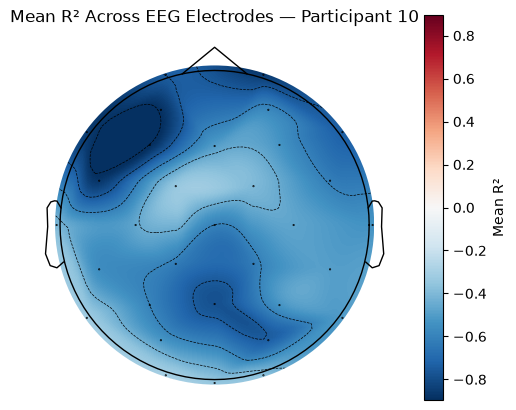

In [239]:
channels = list(mean_r2.channel.values)

picks = [info.ch_names.index(ch) for ch in channels]
info_eeg = mne.pick_info(info, picks)

fig, ax = plt.subplots(figsize=(6, 5))

im, _ = mne.viz.plot_topomap(
    mean_r2.values,
    info_eeg,
    ch_type="eeg",
    cmap="RdBu_r",
    contours=6,
    axes=ax,
    show=False
)

ax.set_title(f"Mean R² Across EEG Electrodes — Participant {participant_id}")

fig.colorbar(im, ax=ax, label="Mean R²")
plt.show()

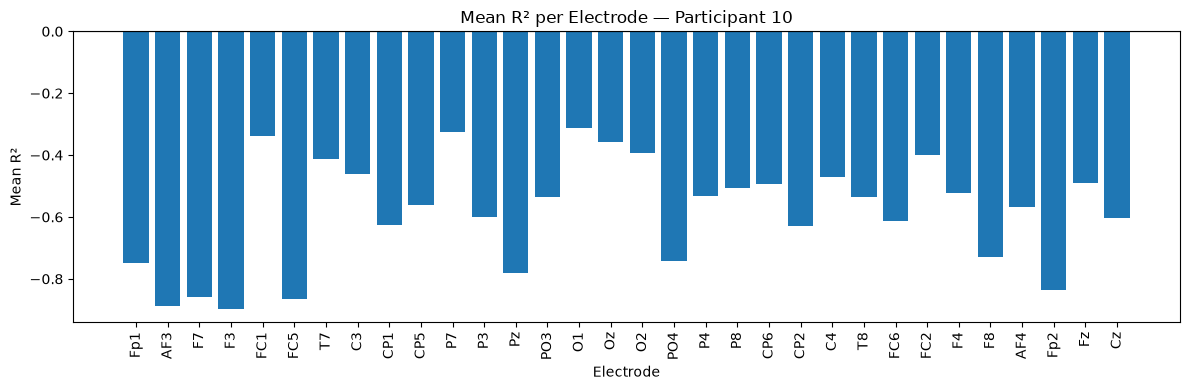

In [240]:
mean_r2 = participant_data.mean(dim="epoch", skipna=True)

plt.figure(figsize=(12, 4))

plt.bar(
    mean_r2.channel.values,
    mean_r2.values
)

plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Mean R²")
plt.xlabel("Electrode")
plt.title(f"Mean R² per Electrode — Participant {participant_id}")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

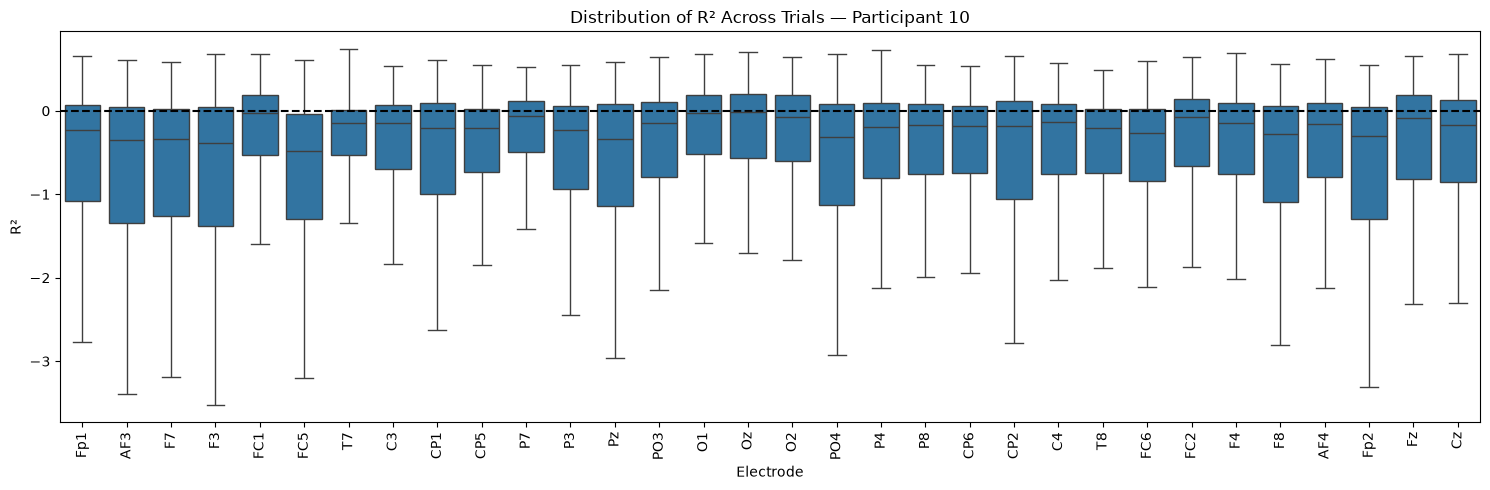

In [241]:
df = participant_data.to_dataframe(name="R2").reset_index()

plt.figure(figsize=(15, 5))

sns.boxplot(
    data=df,
    x="channel",
    y="R2",
    showfliers=False
)

plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Electrode")
plt.ylabel("R²")
plt.title(f"Distribution of R² Across Trials — Participant {participant_id}")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

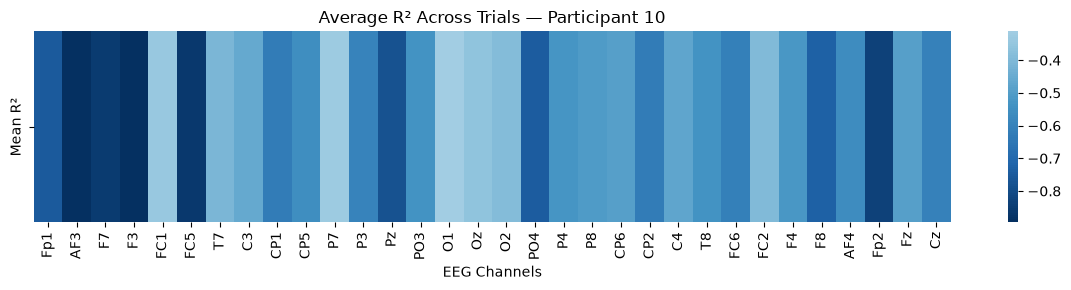

In [242]:
mean_r2 = participant_data.mean(dim="epoch", skipna=True)

plt.figure(figsize=(12, 3))

sns.heatmap(
    mean_r2.values.reshape(1, -1),
    cmap="RdBu_r",
    center=0,
    xticklabels=mean_r2.channel.values,
    yticklabels=["Mean R²"]
)

plt.xlabel("EEG Channels")
plt.title(f"Average R² Across Trials — Participant {participant_id}")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [243]:
for p in range(len(epoch_data.recording)):
    participant_id = epoch_data.recording.values[p]
    print(f"Index: {p}, Participant ID: {participant_id}")

Index: 0, Participant ID: 0
Index: 1, Participant ID: 10


## Does Least Squares Improve Reconstruction of exactly the same EEG trials?

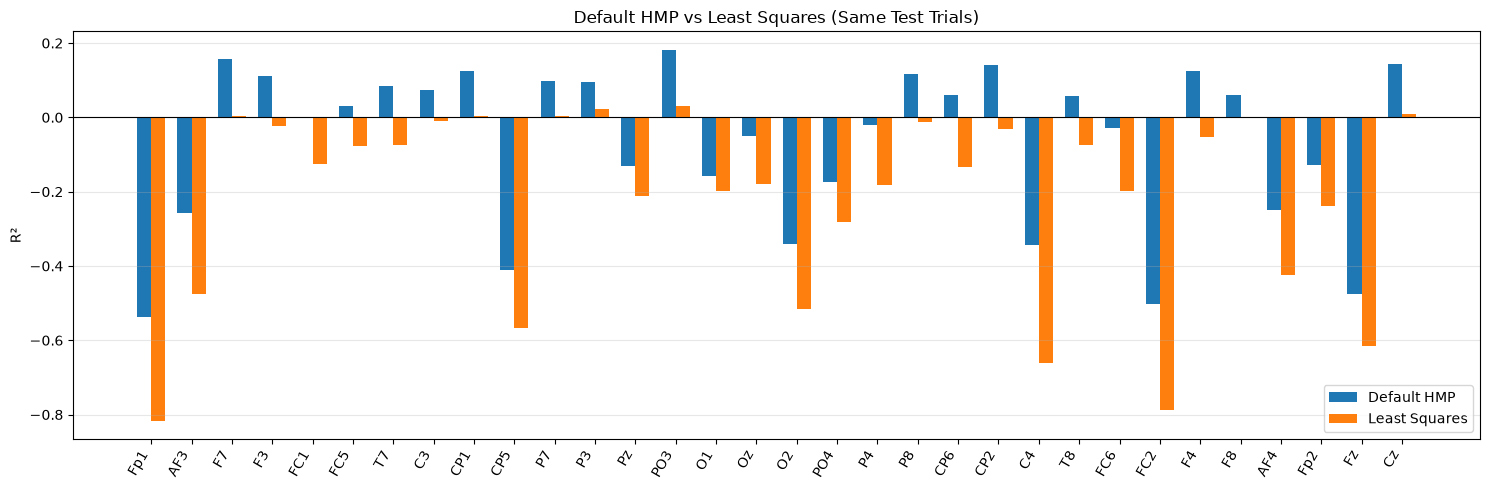

In [244]:

# Default HMP evaluated on the LS test trials

r2_default_test = score(
    only(epoch_data, test),
    only(default_sim, test),
    "r2",
    average_trial=True,
    average_participant=True
)

# Least Squares on the same test trials
r2_ls_test = r2_test_per_electrode

# Compare
fig, ax = plt.subplots(figsize=(15, 5))

x = np.arange(len(channels))
width = 0.35

ax.bar(x - width/2, r2_default_test.values, width,
       label="Default HMP")

ax.bar(x + width/2, r2_ls_test.values, width,
       label="Least Squares")

ax.axhline(0, color="black", linewidth=0.8)

ax.set_xticks(x)
ax.set_xticklabels(channels, rotation=60, ha="right")
ax.set_ylabel("R²")
ax.set_title("Default HMP vs Least Squares (Same Test Trials)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# Improvement

In [245]:
improvement = r2_ls_test - r2_default_test

print("Electrodes improved:",
      int((improvement > 0).sum()), "/", len(channels))

print("Mean R² improvement:", float(improvement.mean()))

Electrodes improved: 0 / 32
Mean R² improvement: -0.1482180265318607


In [256]:
print(type(out))
print(out.keys())

<class 'dict'>
dict_keys(['W', 'pred_uv', 'real_uv', 'test_mask'])


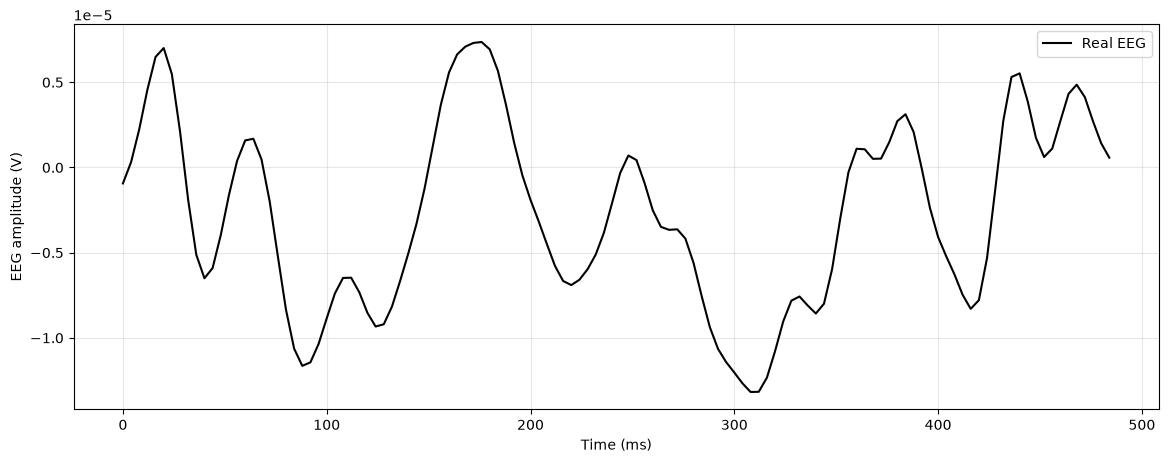

In [275]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(time_ms, real_signal, label="Real EEG", color="black")

ax.set_xlabel("Time (ms)")
ax.set_ylabel("EEG amplitude (V)")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

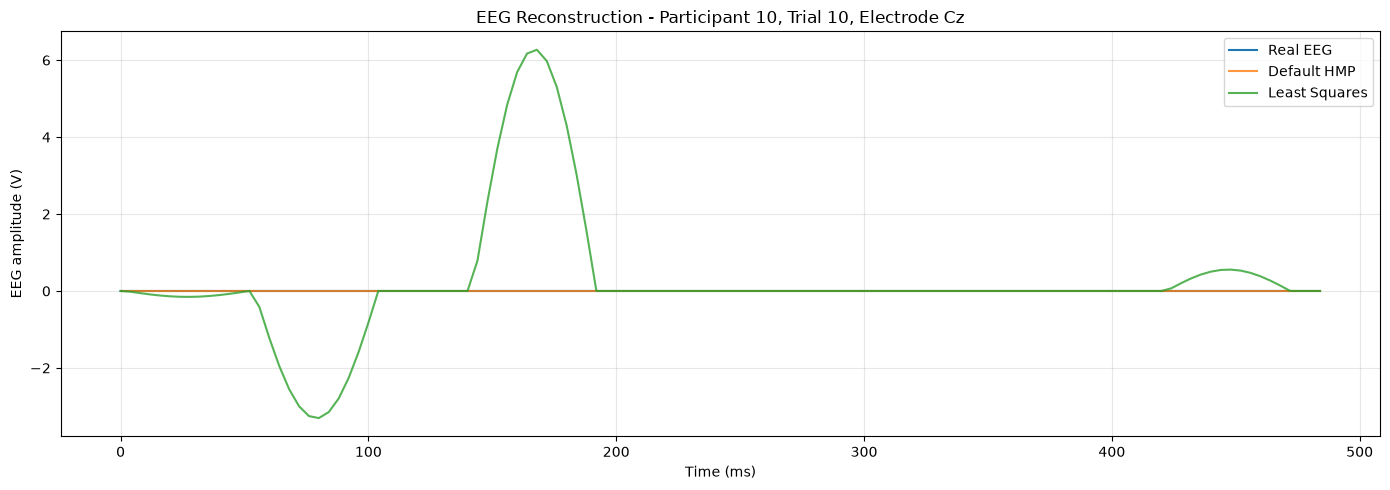

In [273]:

# Choose a participant, trial, and electrode
participant = "10"
trial = 10
electrode = "Cz"

real_signal = epoch_data.sel(
    recording=participant, epoch=trial, channel=electrode
)["data"].values

default_signal = default_sim.sel(
    recording=participant, epoch=trial, channel=electrode
)["data"].values

ls_signal = out["pred_uv"].sel(
    recording=participant, epoch=trial, channel=electrode
)["data"].values

# Plot
fig, ax = plt.subplots(figsize=(14, 5))

time_ms = np.arange(len(real_signal)) * 1000 / SFREQ

ax.plot(time_ms, real_signal, label="Real EEG", linewidth=1.5)
ax.plot(time_ms, default_signal, label="Default HMP", alpha=0.8)
ax.plot(time_ms, ls_signal, label="Least Squares", alpha=0.8)

ax.set_xlabel("Time (ms)")
ax.set_ylabel("EEG amplitude (V)")
ax.set_title(f"EEG Reconstruction - Participant {participant_id}, "
             f"Trial {trial}, Electrode {electrode}")

ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Scalp Topography #

In [249]:

# --------------------------------------------------
# 1. Match the electrode order to the R² scores
# --------------------------------------------------

channels = list(r2_grand.channel.values)

# Keep only the EEG electrodes, in exactly the same order
picks = [info.ch_names.index(ch) for ch in channels]
info_eeg = mne.pick_info(info, picks)

# --------------------------------------------------
# 2. Prepare the three sets of scores
# --------------------------------------------------

scores = [
    (r2_grand.values, "Default HMP"),
    (r2_train_per_electrode.values, "Least Squares - Train"),
    (r2_test_per_electrode.values, "Least Squares - Test")
]

# --------------------------------------------------
# 3. Plot scalp topographies
# --------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (values, title) in zip(axes, scores):

    im, _ = mne.viz.plot_topomap(
        values,
        info_eeg,
        ch_type="eeg",
        axes=ax,
        cmap="RdBu_r",
        vlim=(-1, 1),
        contours=6,
        show=False
    )

    ax.set_title(title, fontsize=12)

# Shared colorbar
fig.colorbar(im, ax=axes, shrink=0.75, label="R² score")

fig.suptitle("EEG Reconstruction Performance Across the Scalp",
             fontsize=15)

plt.tight_layout()
plt.show()


# Combining Ramp Accumulation

In [17]:
# An example using the default assumption of HMP regarding the pattern in the data
pattern_assumption = {0:HalfSine(SFREQ, width=50), 1:HalfSine(SFREQ, width=50),
                      2:HalfSine(SFREQ, width=50), 3:EvidenceAccumulation(SFREQ, drift_rate=.01)}
# one pattern by event (here 4 events)
acc_sim = simulate_from_hmpfit(epoch_data, weights, times, pattern_assumption)
print(acc_sim)

<xarray.Dataset> Size: 220MB
Dimensions:     (recording: 2, epoch: 1116, channel: 32, sample: 768)
Coordinates:
  * recording   (recording) <U1 8B '0' '1'
  * epoch       (epoch) int64 9kB 0 1 2 3 4 5 ... 1110 1111 1112 1113 1114 1115
    event_name  (recording, epoch) object 18kB 'stimulus/95' ... 'stimulus/25'
    rt          (recording, epoch) float64 18kB 0.7197 0.4502 ... 0.4609 0.4082
    condition   (recording, epoch) object 18kB 'accuracy' 'accuracy' ... 'speed'
    side        (recording, epoch) object 18kB 'right' 'right' ... 'right'
    stimulus    (recording, epoch) object 18kB '95' '29' '42' ... '71' '42' '25'
    response    (recording, epoch) object 18kB 'left' 'right' ... 'left' 'right'
    subject     (recording, epoch) <U1 9kB '0' '0' '0' '0' ... '1' '1' '1' '1'
  * channel     (channel) <U3 384B 'Fp1' 'AF3' 'F7' 'F3' ... 'Fp2' 'Fz' 'Cz'
  * sample      (sample) int64 6kB 0 1 2 3 4 5 6 ... 761 762 763 764 765 766 767
Data variables:
    data        (recording, epoch, 

Text(0.5, 1.0, 'Half-Sine and Accumulation')

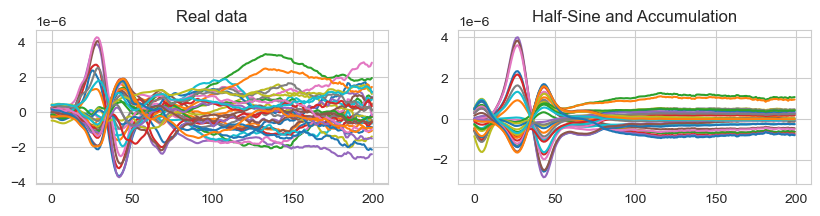

In [18]:
# Plotting the simulation
fig, ax = plt.subplots(1,2, figsize=(10, 2), sharey=False)
ax[0].plot(epoch_data.sel(sample=range(200)).stack({'trial':['epoch','recording']}).mean('trial').data.T);
ax[0].set_title('Real data')
ax[1].plot(acc_sim.sel(sample=range(200)).stack({'trial':['epoch','recording']}).mean('trial').data.T);
ax[1].set_title('Half-Sine and Accumulation')

In [19]:
# ----------------------------------------------------------------------
# Case 1: nothing averaged -> one score per trial and per electrode
# "How well does HMP predict each single trial?"
# dims: (recording, epoch, channel)
# ----------------------------------------------------------------------
r2_trials = score(epoch_data, acc_sim, "r2")

# ----------------------------------------------------------------------
# Case 2: trials averaged -> one score per participant and per electrode
# "How well does HMP predict each participant's average signal (ERP)?"
# dims: (recording, channel)
# ----------------------------------------------------------------------
r2_erp = score(epoch_data, acc_sim, "r2", average_trial=True)

# ----------------------------------------------------------------------
# Case 2b: trials and participants averaged -> one score per electrode
# "How well does HMP predict the grand-average signal, on each electrode?"
# dims: (channel,)
# ----------------------------------------------------------------------
r2_grand = score(epoch_data, acc_sim, "r2",
                 average_trial=True, average_participant=True)

# ----------------------------------------------------------------------
# Case 3: everything averaged -> one single number
# dims: none (a scalar)
# ----------------------------------------------------------------------
r2_global = score(epoch_data, acc_sim, "r2",
                  average_trial=True, average_participant=True, average_channel=True)

print("Case 1  :", r2_trials.shape)
print("Case 2  :", r2_erp.shape)
print("Case 2b :", r2_grand.shape)
print("Case 3  :", float(r2_global))

Case 1  : (2, 1116, 32)
Case 2  : (2, 32)
Case 2b : (32,)
Case 3  : -0.381978235685293


In [20]:
print(r2_grand)

<xarray.DataArray (channel: 32)> Size: 256B
array([-0.52410907, -0.70011619, -0.97773304, -0.46407129, -0.34035397,
       -0.26735219,  0.00283328, -0.07697716, -0.8036776 , -0.19090789,
       -0.11049335, -0.59099181, -0.02390186, -0.29646513, -0.17200538,
       -0.58299369, -0.03725352, -0.62342708, -0.80166471, -0.00425915,
       -0.00670529, -0.07242994, -0.42426827, -0.4335751 , -0.33240033,
       -0.66325066, -0.00793546, -0.02892653, -0.66569501, -0.79005058,
       -0.27464118, -0.93750437])
Coordinates:
  * channel  (channel) <U3 384B 'Fp1' 'AF3' 'F7' 'F3' ... 'AF4' 'Fp2' 'Fz' 'Cz'


In [21]:
window_ms = 50                                   # total window width in ms
half_width = round(window_ms / 1000 * SFREQ / 2) # = 6 at 250 Hz. The window is [event_time - half_width, event_time + half_width]
r2_window = score_event_windows(epoch_data, acc_sim, times, half_width)
print(r2_window.mean("channel"))      # one value per event

<xarray.DataArray (event: 4)> Size: 16B
array([ 0.00921826,  0.01745285,  0.00365176, -0.00259473], dtype=float32)
Coordinates:
  * event    (event) int64 32B 0 1 2 3


In [22]:
# Correlation
# one trial: (samples, channels)
real = epoch_data.sel(sample=range(200)).stack(trial=['epoch', 'recording']).mean('trial')['data'].transpose('sample', 'channel').values
sim  = acc_sim.sel(sample=range(200)).stack({'trial':['epoch','recording']}).mean('trial')['data'].transpose('sample', 'channel').values

print(pearson(real, sim))   # array of shape (n_channels,)


[0.80739486 0.7958881  0.5937509  0.9287025  0.9188097  0.7455119
 0.468454   0.8563364  0.57230836 0.44121113 0.76543593 0.57193375
 0.76930743 0.8777886  0.9054409  0.92541033 0.8339302  0.7000784
 0.15017088 0.7836894  0.27274844 0.7788571  0.79473853 0.7371057
 0.40765166 0.90851974 0.6948651  0.71691096 0.5071419  0.30931634
 0.9310995  0.7584631 ]
